# 중간보고 — 게시글 맥락 추가에 따른 한국어 혐오표현 탐지 (KOCOH v.2)

**연구 질문**: 댓글만으로는 판단하기 어려운 한국어 맥락 의존적 혐오표현에서, 게시글 맥락을 함께 활용하면 혐오표현 탐지 성능을 개선할 수 있는가?
- ① 맥락 정보(Context)가 분류 성능에 미치는 영향
- ② 사전학습 언어모델(PLM)과 전통적 텍스트 분류가 맥락을 활용하는 정도의 차이

| Task | 내용 | 코드 |
|---|---|---|
| **Task 1** | 기준선 (Dummy 2 · 글자 수 LogReg · TF-IDF LogReg · TF-IDF LinearSVC). 통합판 `baseline.py` 는 Context-only 조건과 임계값 조정(train 내부 OOF)까지 포함 | `src/baseline.py` |
| **Task 2** | 본 연구 대상 PLM 2종 × (고정 임베딩 / 전체 fine-tuning / LoRA) — 수치와 결론 내리는 방법 | `src/plm.py` |
| **Task 3** | LoRA(PEFT) vs 전체 fine-tuning — 성능과 비용(학습 파라미터·시간·메모리·저장 크기) 비교 | `src/plm.py` |

**공통 평가 설정** — 모든 모델이 *같은* 5개 fold에서 평가된다.
- 분할: `src/preprocess.py` 의 `cv_splits()` — 같은 Context를 공유하는 Set 묶음(`post_group`) 단위 `StratifiedGroupKFold` 5-fold, stratify=`Hate speech`, seed 42. test 지문은 학습 때 한 번도 보지 않은 지문이다.
- 입력: `get_xy(use_context=False)` → Comment-only / `get_xy(use_context=True)` → Context + Comment. 누설 열(`Type`, 메타 4열, 보조 라벨)은 들어가지 않는다.
- 지표: 정확도 · **macro-F1(주 지표)** · 혐오 클래스 Recall. 5-fold 평균 ± 표준편차(ddof=1).

**자원 제약 (항상 지킴)**: Colab 무료 GPU 수준에서 끝나야 하고, 학습이 있으면 **1회 30분 이내**. 그래서
- 대형 LLM·API 모델은 범위에서 제외하고 base 크기(약 1.1억 파라미터) 한국어 모델만 쓴다.
- 학습(fine-tuning·LoRA)은 epoch 3 · batch 32 · max_length 128 로 고정하고, fold마다 학습 시간을 기록해 30분 상한과 대조한다 (2-5절, 3-3절).

**결과 범위:** 중간발표에는 Task 1의 CPU 기준선을 사용한다. Task 2·3과 아래 종합 결론의 PLM 수치는 팀원이 제공한 이전 탐색 실행 결과이며, 이번 CPU 실행에서 재학습한 결과가 아니다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path('..').resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = Path('.').resolve()  # repo 루트에서 실행하는 경우 (Colab에서 repo 루트로 cd 한 경우 포함)
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

import preprocess as pp

SEED = pp.SEED
np.random.seed(SEED)
pd.set_option('display.width', 200)
print(f"seed = {SEED}")
print(f"데이터 경로: {pp.DATA_PATH.relative_to(PROJECT_ROOT)}")

RUN_TRAINING = False       # PLM 재학습을 직접 실행할 때만 True
CHECK_MODEL_TOKENS = False # 모델을 준비해 토큰 길이를 다시 잴 때만 True

seed = 42
데이터 경로: data/KOCOH_v.2.csv


In [2]:
# 5개 fold를 한 번만 만들어 Task 1·2가 모두 같은 분할을 쓴다 (fold마다 train으로만 전처리)
FOLDS = [(f, tr, te) for f, tr, te, _ in pp.cv_splits()]

seed = 42
원본: 3000행 × 18열

[fold별 크기와 혐오 비율]
      train 행  test 행  test 비율(%)  train 혐오(%)  test 혐오(%)  test 묶음 수
fold                                                                 
0        2410     590      19.667       24.772      28.305          7
1        2375     625      20.833       25.768      24.320         19
2        2382     618      20.600       25.693      24.595         10
3        2411     589      19.633       25.633      24.788         23
4        2422     578      19.267       25.475      25.433         18

[fold 0] 전처리
  누설 열 제외(행 삭제 아님): ['Type', 'Date', 'Source', 'Link', 'Title']
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)
  [test] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)

[fold 1] 전처리
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)
  [test] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)

[fold 2] 전처리
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)
  [test] 결측 행 제거: 0개 


[fold 3] 전처리
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)


  [test] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)

[fold 4] 전처리
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)
  [test] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)


---
# Task 1. 기준선 (`src/baseline.py`)

## 1-1. 왜 이 8개 조합인가 — 각각이 답하는 질문

| 구분 | 기준선 | 답하는 질문 | 입력 조건 | 실행 수 |
|---|---|---|---|---|
| 바닥 | Dummy most_frequent | 전부 '비혐오'라고 하면 몇 점인가? (정확도의 바닥 — 비혐오가 약 75%라 정확도만 보면 아무것도 안 배운 모델도 높다) | 조건 무관 | 1 |
| 바닥 | Dummy stratified | 클래스 비율대로 무작위로 찍으면 몇 점인가? (macro-F1·Recall의 바닥) | 조건 무관 | 1 |
| 진단 | 글자 수만 LogReg | 내용을 읽지 않고 길이라는 표면 특징만으로 맞힐 수 있는가? (지름길 점검) | Comment-only / Context+Comment | 2 |
| 전통 | TF-IDF(char 2–4) + LogReg | 단순한 어휘 모델에서 맥락을 더하면 성능이 오르는가? | Comment-only / Context+Comment | 2 |
| 전통 | TF-IDF(char 2–4) + LinearSVC | 선형 모델 종류를 바꿔도 같은 결론이 나오는가? | Comment-only / Context+Comment | 2 |
| | | | **합계** | **8 조합 × 5 fold = 40회** |

- Context+Comment 는 Context·Comment 를 **각각 별도 TF-IDF** 로 바꿔 옆으로 붙인다(hstack). Comment 쪽 설정이 Comment-only 와 같으므로 두 조건의 차이는 'Context 특성 추가' 하나뿐이다.
- LogReg·LinearSVC 는 `class_weight="balanced"` (혐오 약 25%의 불균형 보정).
- **통합판 `baseline.py` 에 추가된 것**: TF-IDF 두 모델의 Context-only 조건(2조합), 판정 임계값을 train 내부 묶음 4-fold OOF 로 고르는 'OOF 조정' 규칙, PR-AUC, Type별 정답률, Comment-only 이론적 상한. 이 노트북의 표는 중간보고 당시와 같은 8개 조합만 보이고, 나머지는 `python src/baseline.py` 출력과 `results/` 를 본다.
- **뺀 것**: 보조 라벨로 만든 규칙(정답 누설).

## 1-2. 실행 (CPU, 수 초)

`baseline.py` 의 함수를 그대로 불러 같은 fold에서 돌린다. 노트북에서는 결과 파일(`results/baseline_folds.csv`)을 덮어쓰지 않고, 저장된 파일과 같은 값이 나오는지만 확인한다.

In [3]:
import baseline as bl

bl.rows.clear()
for fold, train, test in FOLDS:
    bl.run_fold(fold, train, test)          # '기본' 규칙 10개 조합 (임계값 조정은 python src/baseline.py 에서)
base = pd.DataFrame(bl.rows)

saved = pd.read_csv(PROJECT_ROOT / 'results' / 'baseline_folds.csv')
key = ['model', 'condition', 'fold']
chk = base.merge(saved[saved['rule'] == '기본'], on=key, suffixes=('', '_saved'))
same = len(chk) == len(base) and np.allclose(chk[bl.METRICS].to_numpy(), chk[[m + '_saved' for m in bl.METRICS]].to_numpy(), atol=1e-6)
print(f"results/baseline_folds.csv ('기본' 규칙) 와 동일: {same}  ({len(base)}행 = 10 조합 × 5 fold)")

# 아래 Task 1·2 표는 중간보고 당시와 같은 8개 조합으로 본다 (Context-only 는 baseline.py 출력·로그 참고)
base = base[base['condition'] != 'Context-only'].reset_index(drop=True)

results/baseline_folds.csv ('기본' 규칙) 와 동일: True  (50행 = 10 조합 × 5 fold)


In [4]:
print("[기준선 5-fold 평균 ± 표준편차]")
base_tbl = base.groupby(['model', 'condition'], sort=False)[bl.METRICS].agg(bl.mean_std)
base_tbl

[기준선 5-fold 평균 ± 표준편차]


accuracy       macro_f1    recall_hate
model               condition                                                   
Dummy most_frequent -                0.745 ± 0.016  0.427 ± 0.005  0.000 ± 0.000
Dummy stratified    -                0.608 ± 0.017  0.495 ± 0.024  0.263 ± 0.033
Length LogReg       Comment-only     0.546 ± 0.032  0.532 ± 0.024  0.755 ± 0.083
                    Context+Comment  0.608 ± 0.054  0.562 ± 0.049  0.647 ± 0.248
TF-IDF LogReg       Comment-only     0.719 ± 0.011  0.647 ± 0.014  0.528 ± 0.045
TF-IDF LinearSVC    Comment-only     0.721 ± 0.014  0.644 ± 0.014  0.500 ± 0.031
TF-IDF LogReg       Context+Comment  0.773 ± 0.037  0.633 ± 0.033  0.303 ± 0.031
TF-IDF LinearSVC    Context+Comment  0.783 ± 0.022  0.618 ± 0.034  0.250 ± 0.051

In [5]:
print("[맥락 이득 Δ = (Context+Comment) − (Comment-only), 같은 fold끼리 짝지어 계산]")
bl.context_gain(base).droplevel('rule').loc[['Length LogReg', 'TF-IDF LogReg', 'TF-IDF LinearSVC']]

[맥락 이득 Δ = (Context+Comment) − (Comment-only), 같은 fold끼리 짝지어 계산]


,accuracy,macro_f1,recall_hate
model,,,
Length LogReg,0.062 ± 0.056,0.030 ± 0.058,-0.108 ± 0.246
TF-IDF LogReg,0.054 ± 0.031,-0.014 ± 0.033,-0.225 ± 0.031
TF-IDF LinearSVC,0.061 ± 0.017,-0.025 ± 0.028,-0.250 ± 0.029


## 1-3. Task 1 정리

- **바닥선**: 정확도는 Dummy most_frequent(약 0.745)가, macro-F1·혐오 Recall은 Dummy stratified(macro-F1 약 0.495)가 바닥이다. 이후 모든 모델은 **macro-F1 0.495** 를 넘는지부터 본다.
- **지름길 점검**: 글자 수만으로 macro-F1 약 0.53 — 바닥보다 조금 높아 길이에 약한 신호가 있다. 텍스트 모델 점수를 해석할 때 이 정도는 '길이만으로도 가능한 몫'이다.
- **전통 모델**: TF-IDF 두 모델은 Comment-only 에서 macro-F1 약 0.645 로 바닥을 확실히 넘는다.
- **맥락 효과(전통 모델)**: Context 를 더하면 정확도는 오르지만(+0.05~0.06) macro-F1 Δ는 −0.01~−0.03 으로 fold 간 표준편차(약 0.03) 안이고, **혐오 Recall 은 −0.22~−0.25 로 일관되게 떨어진다**. TF-IDF 에서 맥락 특성은 혐오를 더 잘 찾게 하지 못하고 모델을 비혐오 쪽으로 기울게 한다.

---
# Task 2. 본 연구 대상 모델 — 수치와 결론 내리는 방법

## 2-1. 후보 모델과 선정 이유

| 모델 | 사전학습 데이터 | 선정 이유 | 크기 |
|---|---|---|---|
| **KcELECTRA-base-v2022** (`beomi/KcELECTRA-base-v2022`) | 네이버 뉴스 **댓글** | KOCOH 의 Comment 와 같은 도메인(구어·신조어·비속어) | base, 약 1.2억 파라미터 (488MB) |
| **klue-roberta-base** (`klue/roberta-base`) | 뉴스·위키 등 **일반 한국어** | 댓글 특화가 아닌 표준 한국어 PLM — 도메인 차이 비교용 | base, 약 1.1억 파라미터 (423MB) |

각 모델을 세 방식으로 쓴다.

| 방식 | 내용 | 답하는 질문 | 자원 |
|---|---|---|---|
| **frozen** | 모델 고정, 마지막 층 평균 풀링(768차원) + LogReg(balanced) | 학습 없이 사전학습 표현만으로도 맥락이 도움이 되는가? | CPU로도 수 분 |
| **finetune** | 분류 헤드 + 모델 전체 학습 (epoch 3, batch 32, lr 3e-5, warmup 10%, 클래스 가중 CE) | 모델이 맥락–댓글 관계를 직접 배우면 맥락이 도움이 되는가? | GPU, fold당 수 분 |
| **lora** | 원래 가중치 고정 + 어텐션 query·value 에 LoRA(r=8) + 분류 헤드만 학습 (lr 5e-4, 나머지 동일) | 적은 파라미터만 학습해도 같은 결론이 나오는가? → **Task 3** 에서 자세히 | GPU, fold당 수 분 |

- 입력: Comment-only = `[CLS] Comment [SEP]`, Context+Comment = `[CLS] Context [SEP] Comment [SEP]` (문장쌍).
- **하이퍼파라미터는 고정값만 쓴다.** 별도 검증 셋이 없으므로 test fold를 보고 epoch·lr 을 고르거나 조기 종료하지 않는다.
- 제외: 대형 LLM·API 모델(자원 제약), `model/distilbert-base-uncased`(영어 전용).
- 규모: 2 모델 × 3 방식 × 2 조건 × 5 fold = **60개 결과** (그중 학습이 있는 것은 fine-tuning 20회 + LoRA 20회).
- 모든 결과는 `python src/plm.py` **한 번의 실행**에서 나왔다.

## 2-2. 자원 점검 ① — 최대 입력 길이

문장쌍이 길면 시간·메모리가 늘어난다. 두 토크나이저로 실제 토큰 수를 재서 `max_length=128` 이 충분한지 확인한다.

In [6]:
import os
os.environ.setdefault('HF_HUB_OFFLINE', '1')        # model/ 에 받아 둔 파일만 사용
os.environ.setdefault('TRANSFORMERS_OFFLINE', '1')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

# Colab 처럼 model/ 이 비어 있는 환경에서만 한 번 내려받는다 (로컬에 있으면 건너뜀)
MODEL_FILES = {
    'KcELECTRA-base-v2022': ('beomi/KcELECTRA-base-v2022', ['config.json', 'pytorch_model.bin', 'special_tokens_map.json', 'tokenizer_config.json', 'vocab.txt']),
    'klue-roberta-base': ('klue/roberta-base', ['config.json', 'model.safetensors', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.txt']),
}
if RUN_TRAINING or CHECK_MODEL_TOKENS:
    for name, (repo, files) in MODEL_FILES.items():
        d = PROJECT_ROOT / 'model' / name
        if (d / 'config.json').exists():
            print(f"{name}: 있음 → {d.relative_to(PROJECT_ROOT)}")
        else:
            os.environ['HF_HUB_OFFLINE'] = '0'
            from huggingface_hub import snapshot_download
            snapshot_download(repo, local_dir=d, allow_patterns=files)
            os.environ['HF_HUB_OFFLINE'] = '1'
            print(f"{name}: 내려받음 → {d.relative_to(PROJECT_ROOT)}")
else:
    print("PLM 모델 준비 생략: 저장된 결과 CSV를 사용합니다.")

PLM 모델 준비 생략: 저장된 결과 CSV를 사용합니다.


In [7]:
if RUN_TRAINING or CHECK_MODEL_TOKENS:
    from transformers import AutoTokenizer
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()

    raw = pd.read_csv(pp.DATA_PATH)
    len_rows = {}
    for name in MODEL_FILES:
        tok = AutoTokenizer.from_pretrained(PROJECT_ROOT / 'model' / name)
        c = np.array([len(x) for x in tok(raw['Comment'].tolist())['input_ids']])
        p = np.array([len(x) for x in tok(raw['Context'].tolist(), raw['Comment'].tolist())['input_ids']])
        len_rows[name] = {
            'Comment 중앙값': int(np.median(c)), 'Comment 95%': int(np.percentile(c, 95)), 'Comment 최대': int(c.max()),
            '문장쌍 중앙값': int(np.median(p)), '문장쌍 95%': int(np.percentile(p, 95)), '문장쌍 99%': int(np.percentile(p, 99)),
            '문장쌍 최대': int(p.max()), '128 초과(행)': int((p > 128).sum()),
        }
    print("토큰 수 (특수 토큰 포함), 전체 3,000행")
    display(pd.DataFrame(len_rows).T)
else:
    print("토큰 길이 재측정 생략: CHECK_MODEL_TOKENS=True로 선택 실행합니다.")

토큰 길이 재측정 생략: CHECK_MODEL_TOKENS=True로 선택 실행합니다.


팀 제공 실행에서는 문장쌍도 99%가 100 토큰 미만이고, 128 을 넘는 행은 3,000개 중 한 자릿수다. **max_length=128** 로 두면 거의 잘리지 않으면서 학습 시간을 줄일 수 있다 (넘는 행은 긴 쪽부터 잘림).

## 2-3. 실행 방법

- 학습 40회(fine-tuning 20 + LoRA 20)는 노트북 안에서 돌리기엔 길어서 기본값은 **`src/plm.py` 실행 결과(`results/plm_folds.csv`)를 불러오는 것**이다. 이 파일은 로컬에서 `python src/plm.py` 로 만들었다 (기기는 `device` 열에 기록).
- Colab 에서 직접 재현하려면 첫 설정 셀의 `RUN_TRAINING = True` 로 바꾼다 (런타임 → GPU 선택). `plm.py` 의 같은 함수가 돌고, CUDA 에서는 fp16 autocast 를 쓴다.

In [8]:
if RUN_TRAINING:
    import plm
    device = plm.pick_device()
    print(f"device = {device}")
    plm.rows.clear()
    for name in plm.MODELS:
        for method in plm.METHODS:   # frozen → finetune → lora, 매 fold 마다 results/plm_folds.csv 를 갱신
            if method == 'frozen':
                plm.run_frozen(name, FOLDS, device)
            else:
                plm.run_trained(name, FOLDS, device, method)
plm_csv = PROJECT_ROOT / "results" / "plm_folds.csv"
plm_df = pd.read_csv(plm_csv)
PLM_MODELS = plm_df["model"].drop_duplicates().tolist()
PLM_CONDITIONS = plm_df["condition"].drop_duplicates().tolist()
print(f"{plm_csv.relative_to(PROJECT_ROOT)}: {len(plm_df)}행, device = {sorted(plm_df['device'].unique())}")
print(plm_df.groupby(['model', 'method', 'condition'], sort=False).size().rename('fold 수').to_string())

results/plm_folds.csv: 60행, device = ['mps']
model                 method    condition      
KcELECTRA-base-v2022  frozen    Comment-only       5
                                Context+Comment    5
                      finetune  Comment-only       5
                                Context+Comment    5
                      lora      Comment-only       5
                                Context+Comment    5
klue-roberta-base     frozen    Comment-only       5
                                Context+Comment    5
                      finetune  Comment-only       5
                                Context+Comment    5
                      lora      Comment-only       5
                                Context+Comment    5


## 2-4. 결과 — 기준선과 PLM 을 한 표에

같은 5개 fold, 같은 지표. 위에서부터 바닥 → 진단 → 전통 → PLM 순서.

In [9]:
plm_all = plm_df.assign(model=plm_df['model'] + ' (' + plm_df['method'] + ')')   # 예: klue-roberta-base (finetune)
allres = pd.concat([base[['model', 'condition', 'fold'] + bl.METRICS],
                    plm_all[['model', 'condition', 'fold'] + bl.METRICS]], ignore_index=True)
ORDER = list(dict.fromkeys(allres['model']))

summary = allres.groupby(['model', 'condition'], sort=False)[bl.METRICS].agg(bl.mean_std)
summary

accuracy       macro_f1    recall_hate
model                           condition                                                   
Dummy most_frequent             -                0.745 ± 0.016  0.427 ± 0.005  0.000 ± 0.000
Dummy stratified                -                0.608 ± 0.017  0.495 ± 0.024  0.263 ± 0.033
Length LogReg                   Comment-only     0.546 ± 0.032  0.532 ± 0.024  0.755 ± 0.083
                                Context+Comment  0.608 ± 0.054  0.562 ± 0.049  0.647 ± 0.248
TF-IDF LogReg                   Comment-only     0.719 ± 0.011  0.647 ± 0.014  0.528 ± 0.045
TF-IDF LinearSVC                Comment-only     0.721 ± 0.014  0.644 ± 0.014  0.500 ± 0.031
TF-IDF LogReg                   Context+Comment  0.773 ± 0.037  0.633 ± 0.033  0.303 ± 0.031
TF-IDF LinearSVC                Context+Comment  0.783 ± 0.022  0.618 ± 0.034  0.250 ± 0.051
KcELECTRA-base-v2022 (frozen)   Comment-only     0.706 ± 0.008  0.661 ± 0.012  0.671 ± 0.038
                                Context+Comment  0.718 ± 0.098  0.642 ± 0.099  0.500 ± 0.136
KcELECTRA-base-v2022 (finetune) Comment-only     0.696 ± 0.020  0.672 ± 0.021  0.842 ± 0.036
                                Context+Comment  0.860 ± 0.040  0.809 ± 0.049  0.679 ± 0.106
KcELECTRA-base-v2022 (lora)     Comment-only     0.671 ± 0.033  0.650 ± 0.027  0.847 ± 0.050
                                Context+Comment  0.805 ± 0.063  0.747 ± 0.056  0.636 ± 0.107
klue-roberta-base (frozen)      Comment-only     0.683 ± 0.020  0.634 ± 0.027  0.623 ± 0.060
                                Context+Comment  0.782 ± 0.058  0.715 ± 0.060  0.583 ± 0.105
klue-roberta-base (finetune)    Comment-only     0.660 ± 0.031  0.637 ± 0.028  0.810 ± 0.065
                                Context+Comment  0.831 ± 0.023  0.778 ± 0.012  0.690 ± 0.125
klue-roberta-base (lora)        Comment-only     0.628 ± 0.034  0.606 ± 0.027  0.779 ± 0.066
                                Context+Comment  0.819 ± 0.053  0.776 ± 0.042  0.742 ± 0.089

## 2-5. 자원 점검 ② — 학습 1회 시간 (30분 상한)

`train_sec` = fold 하나의 학습 시간 (frozen 은 전체 임베딩 계산 시간을 fold 수로 나눈 몫 + LogReg 학습).
시간은 기기가 잠든 동안 멈추는 monotonic 시계로 재고, 실제 경과 시간과의 차이는 `sleep_sec` 에 따로 남긴다 → 기기가 잠들어도 학습 시간이 부풀지 않는다.

In [10]:
LIMIT_MIN = 30
t = plm_df.groupby(['model', 'method'], sort=False)['train_sec'].agg(['mean', 'max']).div(60).round(2)
t.columns = ['평균(분)', '최대(분)']
t['30분 이내'] = t['최대(분)'] <= LIMIT_MIN
print(f"기기: {sorted(plm_df['device'].unique())}  — 학습 1회 상한 {LIMIT_MIN}분")
print(f"전체 {len(plm_df)}개 결과의 학습 시간 합계: {plm_df['train_sec'].sum() / 60:.1f}분")
print(f"잠자기로 제외된 시간 합계: {plm_df['sleep_sec'].sum() / 60:.1f}분 (0 이면 측정 중 잠자기 없음)")
t

기기: ['mps']  — 학습 1회 상한 30분
전체 60개 결과의 학습 시간 합계: 126.9분
잠자기로 제외된 시간 합계: 0.0분 (0 이면 측정 중 잠자기 없음)


평균(분)  최대(분)  30분 이내
model                method                        
KcELECTRA-base-v2022 frozen     0.06   0.07    True
                     finetune   3.83   4.75    True
                     lora       2.09   2.86    True
klue-roberta-base    frozen     0.07   0.09    True
                     finetune   4.14   5.25    True
                     lora       2.50   3.31    True

- 위 시간은 로컬 Apple 칩 GPU(MPS, fp32)에서 잰 값이다. Colab 무료 GPU(T4)에서는 `RUN_TRAINING=True` 로 돌리면 같은 `train_sec` 열에 기록되므로 그대로 대조할 수 있다. 데이터 약 2,400행 × epoch 3 × max_length 128 의 base 모델 학습이라 30분 상한과는 여유가 크다.

## 2-6. 결론을 내리는 방법 (판정 규칙)

fold 가 5개뿐이고 test 가 소수의 게시글 묶음으로 이뤄져 fold 간 변동이 크므로, **평균 하나로 결론 내리지 않고 같은 fold끼리 짝지은 차이(Δ)** 로 본다.

**질문 ① 맥락이 도움이 되는가** — 모델마다 Δ = (Context+Comment) − (Comment-only), 주 지표 macro-F1:

| 판정 | 조건 (세 가지 모두) |
|---|---|
| **도움 됨** | 평균 Δ > 0 · 5개 fold 중 4개 이상 Δ > 0 · 대응표본 t-검정 p < 0.05 |
| **해가 됨** | 평균 Δ < 0 · 5개 fold 중 4개 이상 Δ < 0 · p < 0.05 |
| **판단 보류** | 그 밖 (차이가 fold 간 변동에 묻힘) |

혐오 Recall Δ 도 같은 규칙으로 함께 본다 (혐오를 놓치는지가 이 과제의 핵심 오류이므로).

**질문 ② 방법론에 따라 맥락 활용이 다른가** — PLM 의 Δ 와 TF-IDF LogReg 의 Δ 를 같은 fold끼리 다시 뺀 값(ΔΔ)에 같은 규칙을 적용한다.

⚠ n=5 라 t-검정의 검정력이 낮고 부호 검정은 5/5 여도 p=0.0625 다. '판단 보류' 는 '효과 없음' 이 아니라 '이 규모로는 판단할 수 없음' 이다.

In [11]:
from scipy import stats

def verdict(d, labels=('도움 됨', '해가 됨')):
    # d: fold별 차이(5개). 판정 규칙 2-6 을 그대로 적용. labels = (양수 쪽 판정, 음수 쪽 판정)
    t_res = stats.ttest_rel(d, np.zeros_like(d)) if np.any(d != 0) else None
    p = float(t_res.pvalue) if t_res is not None else 1.0
    pos, neg = int((d > 0).sum()), int((d < 0).sum())
    if d.mean() > 0 and pos >= 4 and p < 0.05:
        v = labels[0]
    elif d.mean() < 0 and neg >= 4 and p < 0.05:
        v = labels[1]
    else:
        v = '판단 보류'
    return {'평균 Δ': f"{d.mean():+.3f} ± {d.std(ddof=1):.3f}", 'Δ>0 fold 수': f"{pos}/5", 'p (대응 t)': '<0.001' if p < 0.001 else f"{p:.3f}", '판정': v}

def deltas(model, metric):
    w = allres[allres['model'] == model].pivot(index='fold', columns='condition', values=metric)
    return (w['Context+Comment'] - w['Comment-only']).to_numpy()

MODELS_WITH_COND = [m for m in ORDER if not m.startswith('Dummy')]
q1 = pd.DataFrame({(m, metric): verdict(deltas(m, metric)) for m in MODELS_WITH_COND
                   for metric in ['macro_f1', 'recall_hate']}).T
q1.index.names = ['모델', '지표']
print("질문 ① — 맥락 이득 Δ = (Context+Comment) − (Comment-only)")
q1

질문 ① — 맥락 이득 Δ = (Context+Comment) − (Comment-only)


평균 Δ Δ>0 fold 수 p (대응 t)     판정
모델                              지표                                                    
Length LogReg                   macro_f1     +0.030 ± 0.058        3/5    0.319  판단 보류
                                recall_hate  -0.108 ± 0.246        1/5    0.383  판단 보류
TF-IDF LogReg                   macro_f1     -0.014 ± 0.033        2/5    0.388  판단 보류
                                recall_hate  -0.225 ± 0.031        0/5   <0.001   해가 됨
TF-IDF LinearSVC                macro_f1     -0.025 ± 0.028        0/5    0.114  판단 보류
                                recall_hate  -0.250 ± 0.029        0/5   <0.001   해가 됨
KcELECTRA-base-v2022 (frozen)   macro_f1     -0.019 ± 0.110        2/5    0.723  판단 보류
                                recall_hate  -0.171 ± 0.153        1/5    0.067  판단 보류
KcELECTRA-base-v2022 (finetune) macro_f1     +0.137 ± 0.045        5/5    0.002   도움 됨
                                recall_hate  -0.164 ± 0.101        0/5    0.022   해가 됨
KcELECTRA-base-v2022 (lora)     macro_f1     +0.097 ± 0.072        5/5    0.040   도움 됨
                                recall_hate  -0.211 ± 0.090        0/5    0.006   해가 됨
klue-roberta-base (frozen)      macro_f1     +0.081 ± 0.078        5/5    0.079  판단 보류
                                recall_hate  -0.040 ± 0.139        2/5    0.557  판단 보류
klue-roberta-base (finetune)    macro_f1     +0.141 ± 0.026        5/5   <0.001   도움 됨
                                recall_hate  -0.120 ± 0.118        0/5    0.086  판단 보류
klue-roberta-base (lora)        macro_f1     +0.169 ± 0.052        5/5    0.002   도움 됨
                                recall_hate  -0.037 ± 0.097        1/5    0.444  판단 보류

In [12]:
REF = 'TF-IDF LogReg'
plm_models = [m for m in ORDER if '(' in m]
q2 = pd.DataFrame({(m, metric): verdict(deltas(m, metric) - deltas(REF, metric), labels=('PLM 이득이 더 큼', 'PLM 이득이 더 작음'))
                   for m in plm_models
                   for metric in ['macro_f1', 'recall_hate']}).T
q2.index.names = ['PLM', '지표']
print(f"질문 ② — ΔΔ = Δ(PLM) − Δ({REF}), 같은 fold끼리")
q2

질문 ② — ΔΔ = Δ(PLM) − Δ(TF-IDF LogReg), 같은 fold끼리


평균 Δ Δ>0 fold 수 p (대응 t)           판정
PLM                             지표                                                          
KcELECTRA-base-v2022 (frozen)   macro_f1     -0.005 ± 0.083        3/5    0.908        판단 보류
                                recall_hate  +0.054 ± 0.136        3/5    0.424        판단 보류
KcELECTRA-base-v2022 (finetune) macro_f1     +0.151 ± 0.036        5/5   <0.001  PLM 이득이 더 큼
                                recall_hate  +0.061 ± 0.106        3/5    0.264        판단 보류
KcELECTRA-base-v2022 (lora)     macro_f1     +0.111 ± 0.052        5/5    0.009  PLM 이득이 더 큼
                                recall_hate  +0.014 ± 0.075        4/5    0.690        판단 보류
klue-roberta-base (frozen)      macro_f1     +0.095 ± 0.073        5/5    0.044  PLM 이득이 더 큼
                                recall_hate  +0.185 ± 0.112        5/5    0.021  PLM 이득이 더 큼
klue-roberta-base (finetune)    macro_f1     +0.155 ± 0.034        5/5   <0.001  PLM 이득이 더 큼
                                recall_hate  +0.105 ± 0.126        3/5    0.134        판단 보류
klue-roberta-base (lora)        macro_f1     +0.184 ± 0.035        5/5   <0.001  PLM 이득이 더 큼
                                recall_hate  +0.188 ± 0.098        5/5    0.013  PLM 이득이 더 큼

## 2-7. 그림

저장: figures/kocoh_mid_report.png


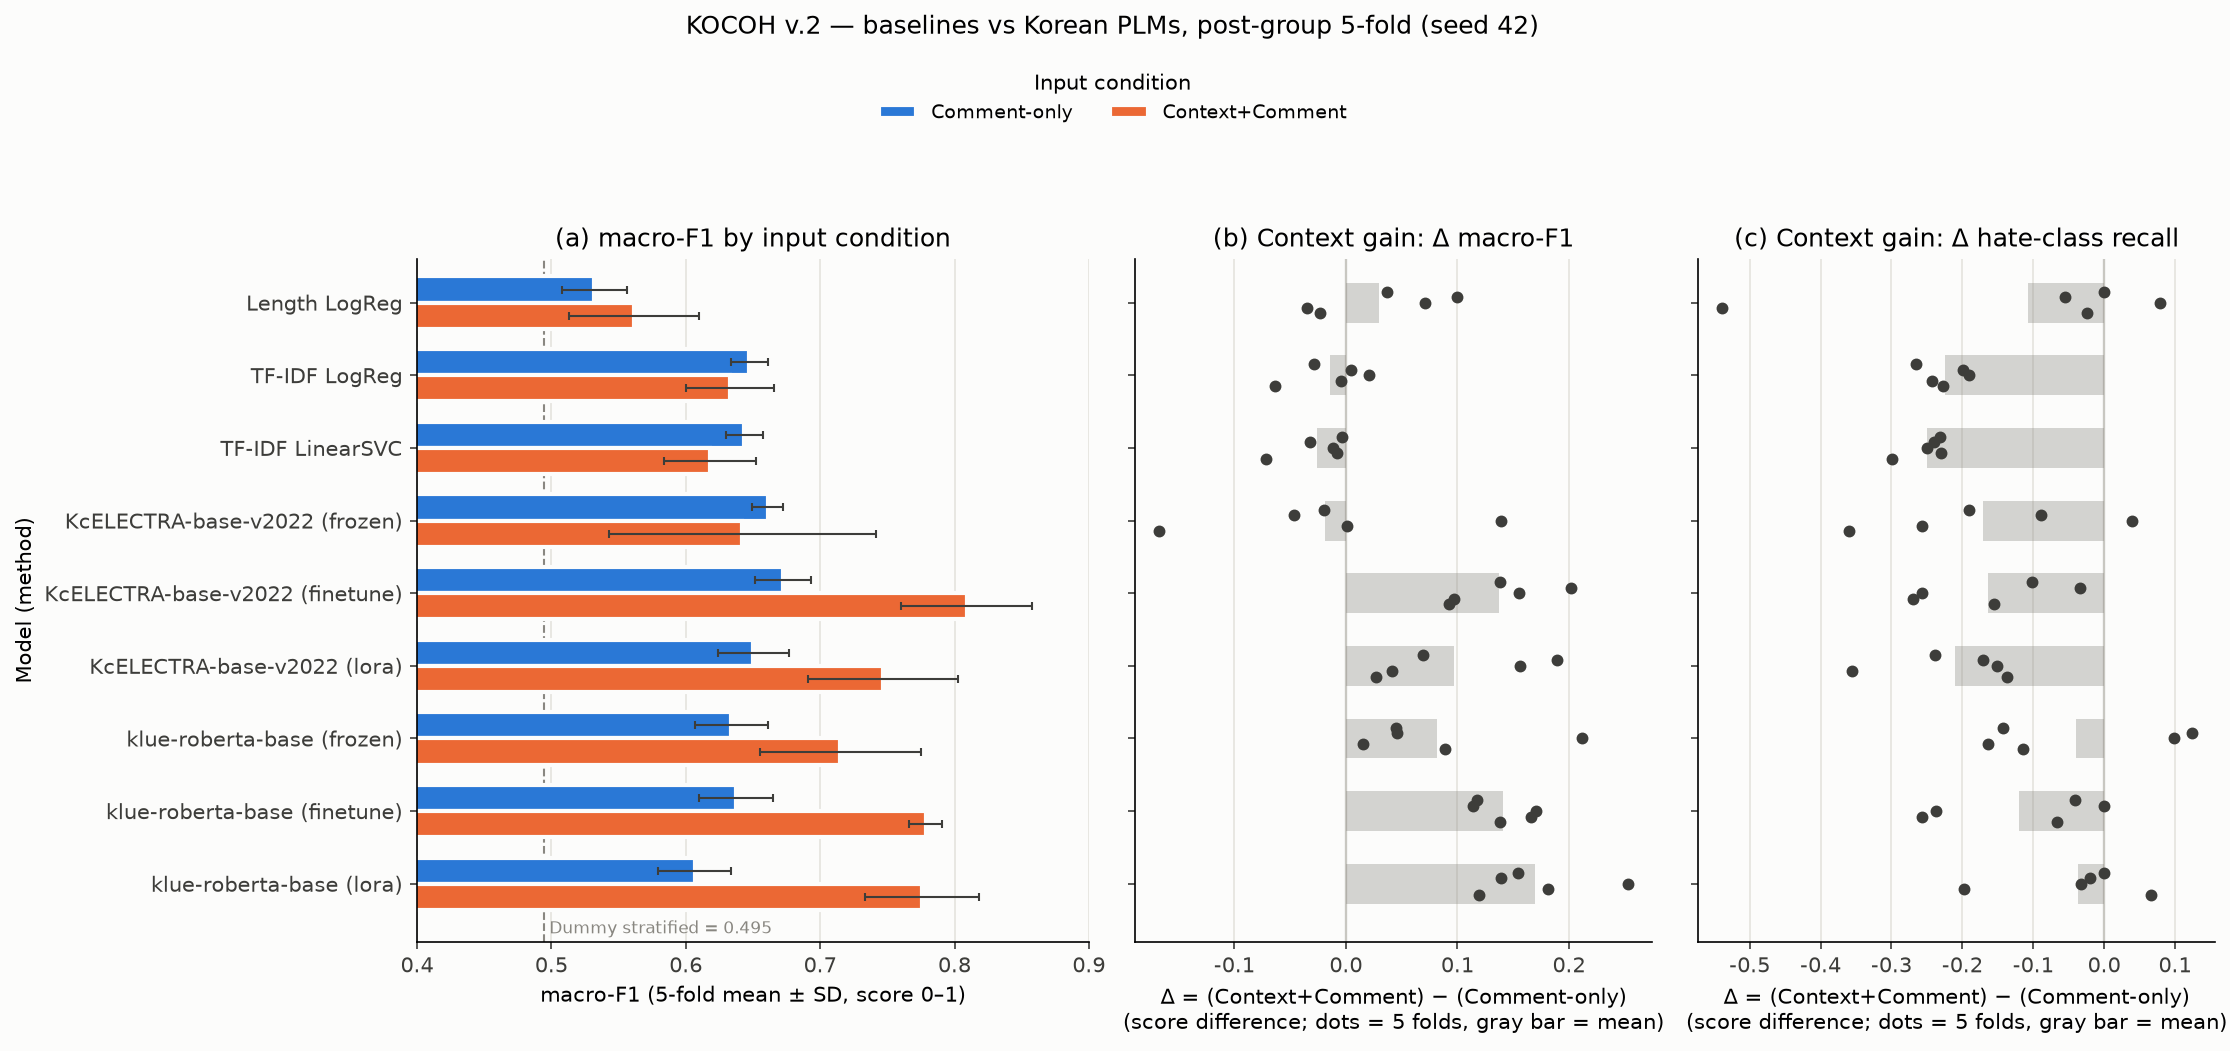

In [13]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "DejaVu Sans"  # 영문 그림과 수학 기호를 동일하게 표시

SURFACE, INK, MUTED, GRID = '#fcfcfb', '#3d3d3a', '#898781', '#e4e3dd'
C_ONLY, C_CTX = '#2a78d6', '#eb6834'   # 범주 1·2번 (preprocess.py 그림과 같은 색)

def style(ax):
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=INK)

models = MODELS_WITH_COND[::-1]          # 위에서부터 기준선 → PLM 이 되도록 뒤집음
y = np.arange(len(models))
fig, axes = plt.subplots(1, 3, figsize=(15, 7), facecolor=SURFACE, sharey=True,
                         gridspec_kw={'width_ratios': [1.3, 1, 1]})

# (a) macro-F1 평균 ± 표준편차, 조건별
ax = axes[0]; style(ax)
h = 0.36
for i, (cond, color) in enumerate([('Comment-only', C_ONLY), ('Context+Comment', C_CTX)]):
    g = allres[allres['condition'] == cond].groupby('model')['macro_f1']
    m, s = g.mean().reindex(models), g.std(ddof=1).reindex(models)
    ax.barh(y + (0.5 - i) * h, m, h, xerr=s, color=color, label=cond, edgecolor=SURFACE, linewidth=2,
            error_kw={'ecolor': INK, 'elinewidth': 1, 'capsize': 2}, zorder=2)
floor = allres[allres['model'] == 'Dummy stratified']['macro_f1'].mean()
ax.axvline(floor, color=MUTED, linestyle='--', linewidth=1, zorder=1)
ax.text(floor, -0.62, f' Dummy stratified = {floor:.3f}', color=MUTED, fontsize=8, va='center')
ax.set_ylim(-0.8, len(models) - 0.4)
ax.set_yticks(y); ax.set_yticklabels(models)
ax.set_xlim(0.4, 0.9)
ax.set_xlabel('macro-F1 (5-fold mean ± SD, score 0–1)')
ax.set_ylabel('Model (method)')
ax.set_title('(a) macro-F1 by input condition')
ax.grid(axis='x', color=GRID, linewidth=0.8, zorder=0)
fig.legend(*ax.get_legend_handles_labels(), title='Input condition', frameon=False, loc='upper center',
           bbox_to_anchor=(0.5, 0.955), ncol=2, fontsize=9)

# (b)(c) fold별 Δ 점 + 평균 막대
for ax, metric, title in [(axes[1], 'macro_f1', '(b) Context gain: Δ macro-F1'),
                          (axes[2], 'recall_hate', '(c) Context gain: Δ hate-class recall')]:
    style(ax)
    for j, mdl in enumerate(models):
        d = deltas(mdl, metric)
        ax.barh(j, d.mean(), 0.55, color=MUTED, alpha=0.35, zorder=2)   # 회색 막대 = 5 fold 평균
        ax.scatter(d, np.full_like(d, j) + np.linspace(-0.15, 0.15, len(d)), s=22, color=INK, zorder=3)
    ax.axvline(0, color=INK, linewidth=1, zorder=1)
    ax.set_xlabel('Δ = (Context+Comment) − (Comment-only)\n(score difference; dots = 5 folds, gray bar = mean)')
    ax.set_title(title)
    ax.grid(axis='x', color=GRID, linewidth=0.8, zorder=0)

fig.suptitle('KOCOH v.2 — baselines vs Korean PLMs, post-group 5-fold (seed 42)', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.86))
FIG = PROJECT_ROOT / 'figures' / 'kocoh_mid_report.png'
fig.savefig(FIG, dpi=150, bbox_inches='tight')
plt.close(fig)
print(f"저장: {FIG.relative_to(PROJECT_ROOT)}")
display(Image(filename=str(FIG), width=1000))

---
# Task 3. LoRA(PEFT) vs 전체 fine-tuning

## 3-1. 무엇을 비교하나

| | 전체 fine-tuning | LoRA (PEFT) |
|---|---|---|
| 학습하는 것 | 모델 전체 + 분류 헤드 | 원래 가중치는 고정. 어텐션 `query`·`value` 옆에 저랭크 행렬 A·B(r=8, alpha=16, dropout 0.1)와 분류 헤드만 학습 |
| 학습률 | 3e-5 | 5e-4 (학습 파라미터가 적어 크게 쓰는 것이 일반적) |
| 그 밖 | epoch 3 · batch 32 · warmup 10% · weight decay 0.01 · 클래스 가중 CE · max_length 128 — **둘 다 같음** | ← |
| 저장물 | 모델 전체 | 어댑터 + 분류 헤드만 (원래 모델은 공유) |

**답하려는 질문**
1. **성능**: 학습 파라미터를 1% 안팎으로 줄여도 macro-F1·혐오 Recall 이 유지되는가?
2. **맥락 이득**: LoRA 에서도 Context 를 넣었을 때의 이득(Task 2 질문 ①)이 같은 크기로 나타나는가? — 결론이 학습 방식에 따라 달라지지 않는지 확인
3. **비용**: 학습 시간·메모리·저장 크기가 얼마나 줄어드는가? (Colab 무료 GPU 제약에서 의미 있는 차이인가)

LoRA 설정은 시험 실행에서 오류·시간·train loss 만 보고 정했고, test 점수를 보고 고르지 않았다.

## 3-2. 성능 비교 (같은 fold, 같은 조건)

In [14]:
FT, LO = 'finetune', 'lora'
two = plm_df[plm_df['method'].isin([FT, LO])]

perf = (two.groupby(['model', 'condition', 'method'], sort=False)[['macro_f1', 'recall_hate', 'accuracy']]
           .agg(bl.mean_std).unstack('method'))
perf.columns = [f"{m} · {me}" for m, me in perf.columns]
print("[5-fold 평균 ± 표준편차]")
perf

[5-fold 평균 ± 표준편차]


macro_f1 · finetune macro_f1 · lora recall_hate · finetune recall_hate · lora accuracy · finetune accuracy · lora
model                condition                                                                                                                        
KcELECTRA-base-v2022 Comment-only          0.672 ± 0.021   0.650 ± 0.027          0.842 ± 0.036      0.847 ± 0.050       0.696 ± 0.020   0.671 ± 0.033
                     Context+Comment       0.809 ± 0.049   0.747 ± 0.056          0.679 ± 0.106      0.636 ± 0.107       0.860 ± 0.040   0.805 ± 0.063
klue-roberta-base    Comment-only          0.637 ± 0.028   0.606 ± 0.027          0.810 ± 0.065      0.779 ± 0.066       0.660 ± 0.031   0.628 ± 0.034
                     Context+Comment       0.778 ± 0.012   0.776 ± 0.042          0.690 ± 0.125      0.742 ± 0.089       0.831 ± 0.023   0.819 ± 0.053

In [15]:
def paired(model, cond, metric, a=LO, b=FT):
    # 같은 fold 끼리 a − b
    w = two[(two['model'] == model) & (two['condition'] == cond)].pivot(index='fold', columns='method', values=metric)
    return (w[a] - w[b]).to_numpy()

lo_vs_ft = pd.DataFrame({(m, c, metric): verdict(paired(m, c, metric), labels=('LoRA 가 더 높음', 'LoRA 가 더 낮음'))
                         for m in PLM_MODELS for c in PLM_CONDITIONS for metric in ['macro_f1', 'recall_hate']}).T
lo_vs_ft.index.names = ['모델', '조건', '지표']
lo_vs_ft = lo_vs_ft.rename(columns={'Δ>0 fold 수': 'LoRA>FT fold 수'})
print("(LoRA) − (전체 fine-tuning), 같은 fold 끼리 — 판정 규칙은 2-6절과 같음")
lo_vs_ft

(LoRA) − (전체 fine-tuning), 같은 fold 끼리 — 판정 규칙은 2-6절과 같음


평균 Δ LoRA>FT fold 수 p (대응 t)           판정
모델                   조건              지표                                                              
KcELECTRA-base-v2022 Comment-only    macro_f1     -0.022 ± 0.034            1/5    0.227        판단 보류
                                     recall_hate  +0.005 ± 0.035            2/5    0.773        판단 보류
                     Context+Comment macro_f1     -0.062 ± 0.046            1/5    0.039  LoRA 가 더 낮음
                                     recall_hate  -0.042 ± 0.108            2/5    0.432        판단 보류
klue-roberta-base    Comment-only    macro_f1     -0.031 ± 0.010            0/5    0.002  LoRA 가 더 낮음
                                     recall_hate  -0.031 ± 0.016            0/5    0.011  LoRA 가 더 낮음
                     Context+Comment macro_f1     -0.003 ± 0.042            2/5    0.898        판단 보류
                                     recall_hate  +0.052 ± 0.089            3/5    0.265        판단 보류

In [16]:
# 맥락 이득이 학습 방식에 따라 달라지는가: Δctx(LoRA) − Δctx(fine-tuning)
gain_cmp = pd.DataFrame({(m, metric): verdict(deltas(f'{m} (lora)', metric) - deltas(f'{m} (finetune)', metric),
                                              labels=('LoRA 의 맥락 이득이 더 큼', 'LoRA 의 맥락 이득이 더 작음'))
                         for m in PLM_MODELS for metric in ['macro_f1', 'recall_hate']}).T
gain_cmp.index.names = ['모델', '지표']
print("맥락 이득 비교 — Δctx(LoRA) − Δctx(fine-tuning), Δctx = (Context+Comment) − (Comment-only)")
gain_cmp

맥락 이득 비교 — Δctx(LoRA) − Δctx(fine-tuning), Δctx = (Context+Comment) − (Comment-only)


평균 Δ Δ>0 fold 수 p (대응 t)                  판정
모델                   지표                                                                 
KcELECTRA-base-v2022 macro_f1     -0.040 ± 0.032        1/5    0.049  LoRA 의 맥락 이득이 더 작음
                     recall_hate  -0.047 ± 0.106        2/5    0.377               판단 보류
klue-roberta-base    macro_f1     +0.028 ± 0.037        4/5    0.163               판단 보류
                     recall_hate  +0.083 ± 0.087        4/5    0.099               판단 보류

## 3-3. 비용 비교 — 학습 파라미터 · 시간 · 메모리 · 저장 크기

- 저장 크기 = 학습한 파라미터 수 × 4 byte (fp32). 전체 fine-tuning 은 모델 전체를, LoRA 는 어댑터 + 분류 헤드만 저장하면 된다.
- 메모리는 학습 중 할당된 GPU 메모리 최대치의 근사값(MPS 는 매 step 측정값 중 최대)이다. 모델 가중치·활성값을 포함하므로 학습 파라미터 비율만큼 줄지는 않는다.
- `train_loss` 는 마지막 epoch 의 학습 손실 평균 (학습이 충분히 진행됐는지 확인용, test 와 무관).

In [17]:
cost = two.groupby(['model', 'method'], sort=False).agg(
    학습파라미터=('trainable_params', 'first'), 전체파라미터=('total_params', 'first'),
    시간평균_분=('train_sec', lambda x: x.mean() / 60), 시간최대_분=('train_sec', lambda x: x.max() / 60),
    메모리최대_GB=('peak_mem_mb', lambda x: x.max() / 1024), train_loss=('train_loss', 'mean'))
cost['학습비율(%)'] = cost['학습파라미터'] / cost['전체파라미터'] * 100
cost['저장크기(MB)'] = cost['학습파라미터'] * 4 / 2**20
cost['30분 이내'] = cost['시간최대_분'] <= LIMIT_MIN
cost = cost[['학습파라미터', '학습비율(%)', '저장크기(MB)', '시간평균_분', '시간최대_분', '메모리최대_GB', 'train_loss', '30분 이내']]
cost.style.format({'학습파라미터': '{:,.0f}', '학습비율(%)': '{:.2f}', '저장크기(MB)': '{:.1f}', '시간평균_분': '{:.2f}',
                   '시간최대_분': '{:.2f}', '메모리최대_GB': '{:.2f}', 'train_loss': '{:.3f}'})

In [18]:
# 같은 (모델, 조건, fold) 끼리 시간 비율 — LoRA 가 몇 배 빠른가
tw = two.pivot_table(index=['model', 'condition', 'fold'], columns='method', values='train_sec')
speed = (tw[FT] / tw[LO]).groupby(level=['model', 'condition']).agg(['mean', 'min', 'max']).round(2)
speed.columns = ['속도비 평균 (FT시간/LoRA시간)', '최소', '최대']
speed

속도비 평균 (FT시간/LoRA시간)    최소    최대
model                condition                                        
KcELECTRA-base-v2022 Comment-only                     2.04  1.89  2.17
                     Context+Comment                  1.73  1.57  1.87
klue-roberta-base    Comment-only                     1.79  1.76  1.86
                     Context+Comment                  1.58  1.53  1.63

## 3-4. 그림

저장: figures/kocoh_lora_vs_finetune.png


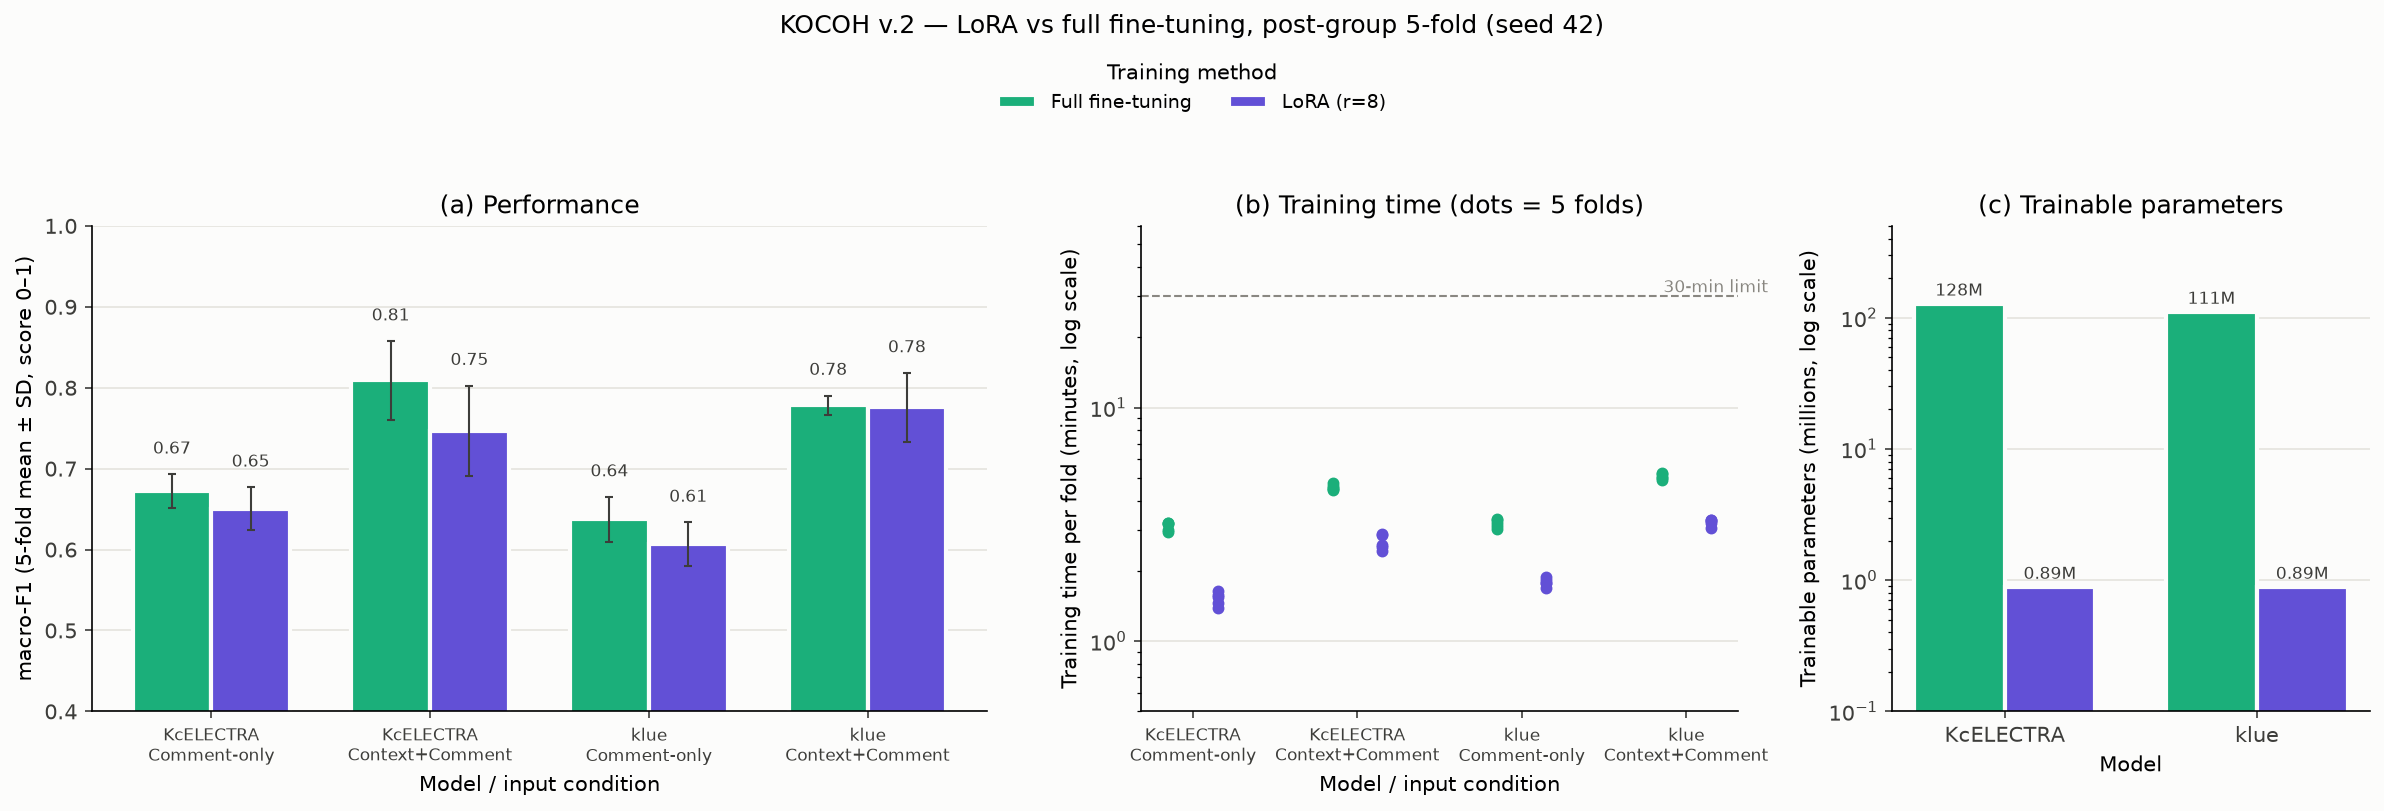

In [19]:
C_FT, C_LO = '#1baf7a', '#6250d6'   # 방식 색 (조건 색 파랑·주황과 겹치지 않게 범주 3·7번)
combos = [(m, c) for m in PLM_MODELS for c in PLM_CONDITIONS]
labels = [f"{m.split('-')[0]}\n{c}" for m, c in combos]
x = np.arange(len(combos))
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4), facecolor=SURFACE, gridspec_kw={'width_ratios': [1.5, 1, 0.8]})

# (a) macro-F1
ax = axes[0]; style(ax)
w = 0.36
for i, (meth, color, name) in enumerate([(FT, C_FT, 'Full fine-tuning'), (LO, C_LO, 'LoRA (r=8)')]):
    g = two[two['method'] == meth].groupby(['model', 'condition'])['macro_f1']
    mu = np.array([g.mean()[k] for k in combos]); sd = np.array([g.std(ddof=1)[k] for k in combos])
    bars = ax.bar(x + (i - 0.5) * w, mu, w, yerr=sd, color=color, label=name, edgecolor=SURFACE, linewidth=2,
                  error_kw={'ecolor': INK, 'elinewidth': 1, 'capsize': 2}, zorder=2)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in mu], padding=8, fontsize=8, color=INK)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel('Model / input condition')
ax.set_ylabel('macro-F1 (5-fold mean ± SD, score 0–1)')
ax.set_title('(a) Performance')
ax.grid(axis='y', color=GRID, linewidth=0.8, zorder=0)

# (b) 학습 1회 시간 (분) — fold별 점
ax = axes[1]; style(ax)
for i, (meth, color) in enumerate([(FT, C_FT), (LO, C_LO)]):
    for j, k in enumerate(combos):
        v = two[(two['method'] == meth) & (two['model'] == k[0]) & (two['condition'] == k[1])]['train_sec'] / 60
        ax.scatter(np.full(len(v), j + (i - 0.5) * 0.3), v, s=22, color=color, zorder=3)
ax.axhline(LIMIT_MIN, color=MUTED, linestyle='--', linewidth=1)
ax.text(len(combos) - 0.5, LIMIT_MIN, '30-min limit', color=MUTED, fontsize=8, ha='right', va='bottom')
ax.set_yscale('log'); ax.set_ylim(0.5, 60)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_xlabel('Model / input condition')
ax.set_ylabel('Training time per fold (minutes, log scale)')
ax.set_title('(b) Training time (dots = 5 folds)')
ax.grid(axis='y', color=GRID, linewidth=0.8, zorder=0)

# (c) 학습 파라미터 수 (백만, 로그)
ax = axes[2]; style(ax)
mods = list(PLM_MODELS)
xm = np.arange(len(mods))
for i, (meth, color) in enumerate([(FT, C_FT), (LO, C_LO)]):
    v = [two[(two['method'] == meth) & (two['model'] == m)]['trainable_params'].iloc[0] / 1e6 for m in mods]
    bars = ax.bar(xm + (i - 0.5) * w, v, w, color=color, edgecolor=SURFACE, linewidth=2, zorder=2)
    ax.bar_label(bars, labels=[f"{t:.2f}M" if t < 10 else f"{t:.0f}M" for t in v], padding=2, fontsize=8, color=INK)
ax.set_yscale('log'); ax.set_ylim(0.1, 500)
ax.set_xticks(xm); ax.set_xticklabels([m.split('-')[0] for m in mods])
ax.set_xlabel('Model')
ax.set_ylabel('Trainable parameters (millions, log scale)')
ax.set_title('(c) Trainable parameters')
ax.grid(axis='y', color=GRID, linewidth=0.8, zorder=0)

fig.legend(*axes[0].get_legend_handles_labels(), title='Training method', frameon=False, loc='upper center',
           bbox_to_anchor=(0.5, 0.955), ncol=2, fontsize=9)
fig.suptitle('KOCOH v.2 — LoRA vs full fine-tuning, post-group 5-fold (seed 42)', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.86))
FIG3 = PROJECT_ROOT / 'figures' / 'kocoh_lora_vs_finetune.png'
fig.savefig(FIG3, dpi=150, bbox_inches='tight')
plt.close(fig)
print(f"저장: {FIG3.relative_to(PROJECT_ROOT)}")
display(Image(filename=str(FIG3), width=1000))

---
# 결론 (팀 제공 PLM 탐색 실행 포함)

모든 수치는 같은 post_group 5-fold(seed 42)에서 얻은 평균 ± 표준편차다. 판정은 2-6절 규칙(평균 Δ 부호 + 5개 중 4개 이상 fold 같은 방향 + 대응 t-검정 p<0.05)을 따른다. PLM 60개 결과는 한 번의 실행(잠자기 0분)에서 나왔다.

## 1. 한눈에 보기 — macro-F1 (주 지표)

| 모델 | Comment-only | Context+Comment | 맥락 이득 Δ | Δ>0 fold | 판정 |
|---|---|---|---|---|---|
| Dummy stratified (바닥) | 0.495 ± 0.024 | — | — | — | — |
| TF-IDF LogReg | 0.647 ± 0.014 | 0.633 ± 0.033 | −0.014 ± 0.033 | 2/5 | 판단 보류 |
| TF-IDF LinearSVC | 0.644 ± 0.014 | 0.618 ± 0.034 | −0.025 ± 0.028 | 0/5 | 판단 보류 |
| KcELECTRA (frozen) | 0.661 ± 0.012 | 0.642 ± 0.099 | −0.019 ± 0.110 | 2/5 | 판단 보류 |
| klue-roberta (frozen) | 0.634 ± 0.027 | 0.715 ± 0.060 | +0.081 ± 0.078 | 5/5 | 판단 보류 (p=0.079) |
| **KcELECTRA (fine-tuning)** | 0.672 ± 0.021 | **0.809 ± 0.049** | **+0.137 ± 0.045** | **5/5** | **도움 됨** (p=0.002) |
| **klue-roberta (fine-tuning)** | 0.637 ± 0.028 | **0.778 ± 0.012** | **+0.141 ± 0.026** | **5/5** | **도움 됨** (p<0.001) |
| KcELECTRA (LoRA) | 0.650 ± 0.027 | 0.747 ± 0.056 | +0.097 ± 0.072 | 5/5 | 도움 됨 (p=0.040) |
| klue-roberta (LoRA) | 0.606 ± 0.027 | 0.776 ± 0.042 | +0.169 ± 0.052 | 5/5 | 도움 됨 (p=0.002) |

## 2. 연구 질문에 대한 답

**① 맥락 정보는 성능에 영향을 주는가 → 모델이 맥락을 '학습'할 때만 도움이 된다.**
- 학습시킨 PLM 4가지(2모델 × fine-tuning/LoRA)는 모두 Context 를 넣으면 macro-F1 이 **+0.10~+0.17** 오르고, 5개 fold 모두에서 올랐다 (전부 '도움 됨').
- TF-IDF 두 모델과 KcELECTRA 고정 임베딩은 Context 를 넣어도 macro-F1 이 오르지 않았다(Δ −0.01~−0.03, 판단 보류). klue-roberta 고정 임베딩은 5/5 fold 에서 올랐지만(+0.081) 유의 기준에는 못 미쳤다.
- **주의 — 혐오 Recall 은 거의 모든 모델에서 내려간다.** fine-tuning KcELECTRA 0.842→0.679('해가 됨'), klue-roberta 0.810→0.690(판단 보류), LoRA KcELECTRA 0.847→0.636('해가 됨'). 같은 모델에서 정확도는 0.70→0.86, 0.66→0.83 으로 크게 오르므로, **맥락의 이득은 주로 '비혐오 댓글을 혐오로 잘못 판정하던 오탐'이 줄어든 데서 온다.** 대신 혐오를 일부 더 놓친다. 예외로 klue-roberta LoRA 는 Recall 저하가 −0.037(판단 보류)로 작았다.

**② 방법론에 따라 맥락 활용이 다른가 → 그렇다. 사전학습 모델을 '학습'시키면 전통 모델보다 맥락을 훨씬 잘 쓴다.**
- TF-IDF LogReg 대비 맥락 이득의 차이(ΔΔ, macro-F1): fine-tuning KcELECTRA **+0.151**, klue-roberta **+0.155**, LoRA KcELECTRA **+0.111**, klue-roberta **+0.184** — 넷 다 5/5 fold, p<0.01 로 'PLM 이득이 더 큼'.
- 고정 임베딩은 엇갈린다: klue-roberta frozen +0.095(p=0.044, 'PLM 이득이 더 큼'), KcELECTRA frozen −0.005(판단 보류, Context+Comment 에서 fold 간 표준편차 0.099 로 매우 불안정).
- 정리하면, TF-IDF 처럼 Context 를 '단어 묶음' 으로만 더하면 효과가 없고, **Context 와 Comment 를 한 입력(문장쌍)으로 넣어 관계를 학습시킬 때** 효과가 난다.

**도메인(댓글 특화 vs 일반 한국어)**: fine-tuning 에서 KcELECTRA 가 조금 높지만(0.809 vs 0.778), 그 차이 0.03 은 실행 간 흔들림(4절 한계 2)과 같은 크기라 **어느 쪽이 낫다고 말할 수 없다.**

## 3. Task 3 — LoRA vs 전체 fine-tuning

| 항목 | 전체 fine-tuning | LoRA (r=8, query·value) |
|---|---|---|
| 학습 파라미터 | KcELECTRA 127.8M / klue 110.6M (100%) | 0.89M (KcELECTRA 0.69%, klue 0.80%) |
| 저장 크기 (fp32, 학습분만) | 487 MB / 422 MB | **3.4 MB** |
| 학습 1회 평균 (Comment-only / Context+Comment) | KcELECTRA 3.1 / 4.6분, klue 3.2 / 5.1분 | KcELECTRA 1.5 / 2.7분, klue 1.8 / 3.2분 |
| 속도비 (FT 시간 ÷ LoRA 시간) | — | 1.6~2.0배 빠름 |
| 최대 메모리 (MPS) | 5.2~5.5 GB | 4.5 GB |
| macro-F1, Comment-only | 0.672 / 0.637 | 0.650 / 0.606 |
| macro-F1, Context+Comment | 0.809 / 0.778 | 0.747 / 0.776 |

- **성능**: LoRA 는 4개 조합 모두 평균이 fine-tuning 보다 낮거나 같다 (−0.003~−0.062). 판정상 'LoRA 가 더 낮음' 은 KcELECTRA Context+Comment(−0.062, p=0.039)와 klue Comment-only(−0.031, p=0.002) 두 곳이고, 나머지 두 곳은 판단 보류다. klue Context+Comment 는 사실상 같다(−0.003).
- **맥락 이득**: LoRA 로 바꿔도 맥락 이득은 그대로 크게 남는다(+0.097, +0.169). 이득 크기 비교 Δctx(LoRA) − Δctx(FT) 는 KcELECTRA −0.040('LoRA 의 맥락 이득이 더 작음', p=0.049), klue +0.028(판단 보류)로 모델마다 방향이 다르다. → **"맥락이 도움이 된다" 는 결론은 학습 방식(전체 / LoRA)에 관계없이 유지된다.**
- **비용**: 학습 파라미터는 약 1/140, 저장 크기 약 1/130, 학습 시간 약 1/2, 메모리는 약 15~18% 적다. 메모리 절감이 작은 것은 batch 32 × 문장쌍의 활성값(activation)이 대부분이라서다. 이 데이터 규모(3,000행)에서는 fine-tuning 도 1회 5.3분 이하라 **30분 상한에는 둘 다 충분하다**. LoRA 의 실질 이점은 '시간 절반'과 '실험마다 3.4 MB 어댑터만 저장' 이다.
- **해석 주의**: lr(5e-4 vs 3e-5)과 epoch 3 은 test 를 보지 않고 정한 관행값이다. LoRA 는 보통 epoch 을 더 늘려야 전체 fine-tuning 에 근접하므로, 이번 차이는 '같은 epoch 예산에서' 의 비교다. train_loss 도 LoRA 가 더 높게 끝났다(Context+Comment 0.24~0.30 vs 0.11~0.19) — 덜 수렴했을 가능성.

## 4. 자원 점검 — Colab 무료 GPU · 학습 1회 30분 이내

| 항목 | 측정값 | 상한 대비 |
|---|---|---|
| fine-tuning 1회 (fold 하나, epoch 3) | KcELECTRA 평균 3.8분 · 최대 4.8분 / klue 평균 4.1분 · 최대 5.3분 | 30분의 약 1/6 |
| LoRA 1회 | KcELECTRA 평균 2.1분 · 최대 2.9분 / klue 평균 2.5분 · 최대 3.3분 | 30분의 약 1/10 |
| 고정 임베딩 + LogReg 1회 | 0.1분 이하 | 충분 |
| 기준선 8조합 × 5 fold 전체 | 수 초 (CPU) | 충분 |
| PLM 60개 결과 전체 | 학습 시간 합계 126.9분 (실행 시작~끝 2시간 10분) | 1회 상한과 별개, 여러 세션으로 나눌 수 있음 |
| 최대 입력 길이 | 128 토큰 (128 초과 문장쌍 5~8 / 3,000행) | 메모리 여유 |

- 측정 기기는 로컬 Apple 칩 GPU(MPS, fp32)다. **Colab T4 에서는 아직 재지 않았다** — `RUN_TRAINING=True` 로 돌리면 같은 `train_sec` 열에 기록되어 대조할 수 있다 (CUDA 에서는 fp16 autocast 사용).
- 시간은 잠자기 시간을 빼는 시계(monotonic)로 쟀고, 이번 실행의 잠자기 시간 합계는 0분이다.

## 5. 한계

1. **PLM Context-only를 돌리지 않았다** → 맥락 이득이 '맥락–댓글 관계 이해' 인지, '게시글 주제별 혐오 비율' 을 따라간 것인지 구분하지 못한다.
2. **seed 하나, fold 다섯 개.** 같은 seed·설정으로 처음부터 다시 돌린 이번 실행과 이전 실행(원본 기록은 이 통합본에 포함되지 않음)을 fold별로 비교하면 fine-tuning macro-F1 이 평균 0.013, 최대 0.051 달라졌다 (GPU 연산의 비결정성; 고정 임베딩은 차이 0). 모델 간·방식 간 0.03 내외 차이는 해석하지 않는다.
3. **혐오 Recall 저하.** class 가중 손실을 썼는데도 Context 를 넣으면 Recall 이 대부분 0.1~0.2 떨어진다. 판정 임계값(argmax)은 조정하지 않았다.
4. **하이퍼파라미터 미탐색.** epoch 3 · lr(3e-5 / LoRA 5e-4) · LoRA r=8 고정값만 썼다 (test fold 로 고르지 않기 위해).
5. **test 묶음 수가 적은 fold** (fold 0: 7개 묶음, 혐오 28.3%) 가 있어 fold별 점수 차가 크다.

## 6. 다음 단계 (모두 같은 자원 상한 안)

| 우선 | 할 일 | 비용 |
|---|---|---|
| 1 | **seed 3개 반복** (fine-tuning 또는 LoRA, 2모델 × 2조건 × 5 fold × 3 seed) → 실행 간 흔들림을 정식으로 추정하고 도메인·방식 비교 판단 | fine-tuning 60회 ≈ 4시간 / LoRA 로 하면 ≈ 2.3시간 (1회는 모두 6분 이내) |
| 2 | **Recall 회복**: train 안에서 떼어 낸 검증 분할로 판정 임계값 조정 | 추가 학습 없음 (예측 확률만 저장) |
| 3 | **오류 분석**: `Type`(1·2·3)별 정답률 — `Type` 은 입력에 넣지 않고 **분석용으로만** 사용 | 추가 학습 없음 |
| 4 | **LoRA epoch 늘리기** (train 안 검증 분할로 epoch 선택) → 같은 시간 예산에서 fine-tuning 과 대등한지 | 1회 약 5분 |
| 5 | **Colab T4 시간 측정**: `RUN_TRAINING=True` 로 1 fold 실행해 30분 상한 재확인 | 1~2회 |

## 요약 (실험 이름 / 설정 / 지표 / 결과 파일)

- **실험 이름**: baseline / plm (중간보고 project_mid_report, Task 1·2·3)
- **설정**: split=post_group 5-fold StratifiedGroupKFold, seed=42, stratify=Hate speech · 기준선: TF-IDF char_wb(2,4) + LogReg/LinearSVC(class_weight=balanced), 글자 수 LogReg, Dummy 2종 · PLM: KcELECTRA-base-v2022, klue-roberta-base × (frozen 평균 풀링 + LogReg / fine-tuning lr=3e-5 / LoRA r=8, α=16, query·value, lr=5e-4) · 공통 epoch=3, batch=32, warmup=0.1, max_len=128, 클래스 가중 CE · device=mps
- **지표 (macro-F1, Comment-only → Context+Comment)**: TF-IDF LogReg 0.647→0.633 · fine-tuning KcELECTRA 0.672→0.809 (Δ +0.137, 5/5, p=0.002), klue 0.637→0.778 (Δ +0.141, 5/5, p<0.001) · LoRA KcELECTRA 0.650→0.747 (Δ +0.097, p=0.040), klue 0.606→0.776 (Δ +0.169, p=0.002) · LoRA 학습 파라미터 0.89M(0.7~0.8%), 시간 1.6~2.0배 빠름 · 학습 1회 최대 5.3분 (MPS)
- **결과 파일**: `results/baseline_folds.csv`, `results/plm_folds.csv` (60행), `figures/kocoh_mid_report.png`, `figures/kocoh_lora_vs_finetune.png` · 코드 `src/baseline.py`, `src/plm.py`